## Objectives:
1. Detect and quantify missing data patterns in a dataset.
2. Choose the right strategy for different tpes of missingness.
3. Implement imputation using sklearn SimpleImputer and KNNImputer.

## Handling Missing Data
### Understand why data is missing? -> Understanding missingness mechanisms.

### 1. MCAR - Missing Completely At Random
- Missingness has no pattern e.g Sensor glitch.

#### Strategy:
- Drop rows (if small %)
- Simple imputation with mean/ median.

Why it is safe, because missingness does not bias the dataset.

### 2. MAR - Missing At Random.
Missingmness depends on other obsereved features.   e.g. Older patients are less likely to report income.

#### Strategy.
Use models that leverage relationships (Imputation using related features).
- Knn Imputer.
- Regression-based imputation.
Because other features contain useful clues.

### 3. MNAR - Missing Not At Random.
Missingness is related to the missing value itself.
The missingness depends on unobserved information, making it systematic rather than random.
" Most problem - create an 'is_missing' flag feature."

#### Handling MNAR data:
- Sensitivity analysis : Testing how different assumptions about the missing data affect 
the results.
- Modelling: Using advanced models that explicitly model the missingness mechanisms.
- Auxiallary data: Incorporating additional variables that might correlate with the missing value.

FLAG + IMPUTATION.

In [3]:
import pandas as pd
import numpy as np

df = pd.read_csv('Titanic-Dataset.csv')


In [7]:
print(f'Shape:',df.shape)

Shape: (891, 12)


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [29]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [10]:
print("Missing Values Percentages:")
print((df.isnull().mean()*100).round(1))

Missing Values Percentages:
PassengerId     0.0
Survived        0.0
Pclass          0.0
Name            0.0
Sex             0.0
Age            19.9
SibSp           0.0
Parch           0.0
Ticket          0.0
Fare            0.0
Cabin          77.1
Embarked        0.2
dtype: float64


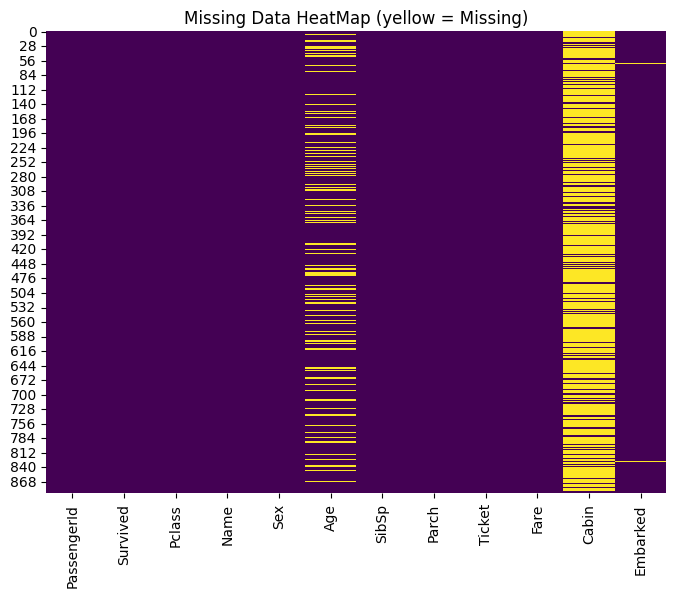

In [54]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,6))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title('Missing Data HeatMap (yellow = Missing)')
plt.show()




In [22]:
missing_df = pd.DataFrame({
    'missing_count': df.isnull().sum(),
    'missing_percentage': (df.isnull().mean()*100).round(1)
})

print(missing_df[missing_df['missing_count']>0].sort_values('missing_percentage', ascending=False))


          missing_count  missing_percentage
Cabin               687                77.1
Age                 177                19.9
Embarked              2                 0.2


## Dropping rows/columns
We drop data only when it is safe or useless.
You drop when you have 50% of missing data.

In [51]:
df_clean = df.drop(columns = ['Cabin'])
df_clean = df_clean.dropna(subset=['Embarked'])
print('After dropping', df_clean.shape)
print('Missing in Age', df_clean['Age'].isnull().sum())

After dropping (889, 11)
Missing in Age 177


## Imputation

### Strategy 2: Simple Imputation
#### Numeric median 

In [33]:
from sklearn.impute import SimpleImputer

age_imputer = SimpleImputer(strategy='median')
df_clean['Age']= age_imputer.fit_transform(df_clean[['Age']])

## How to deal with Categorical Features
Categorical -> We are going to fill in using most Frequent


In [35]:
df_clean2 =df.drop(columns = ['Cabin'])


In [52]:
emb_imputer = SimpleImputer(strategy='most_frequent')
df_clean2['Embarked']= emb_imputer.fit_transform(df_clean2[['Embarked']]).ravel()

## Strategy 3: KNN Imputation
As matter method that looks at similar rows.
KNN only works on numerical data.


In [53]:
from sklearn.impute import KNNImputer

knn_imputer = KNNImputer(n_neighbors=5)
numeric_columns = ['Pclass','Age','SibSp','Parch','Fare']

df_knn = df[numeric_columns.copy()]

df_filled = pd.DataFrame(
    knn_imputer.fit_transform(df_knn), 
    columns=numeric_columns
    )

df_filled.isnull().sum()



Pclass    0
Age       0
SibSp     0
Parch     0
Fare      0
dtype: int64

In [48]:
df['Age'].mean()

np.float64(29.69911764705882)

In [49]:
df_filled['Age'].mean()

np.float64(29.863791245791244)

In [50]:
df_clean['Age'].mean()

np.float64(29.315151856017994)